In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Descargar datos históricos del dólar (USD/MXN como referencia de tipo de cambio)
ticker = 'MXN=X'

# Obtener datos de los últimos 3 años
data = yf.download(ticker, period='3y')

/tmp/ipykernel_4245/715114212.py:10: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, period='3y')
[*********************100%***********************]  1 of 1 completed


In [ ]:
# Calcular los retornos logarítmicos diarios
close_prices = data['Close']
log_returns = np.log(close_prices / close_prices.shift(1)).dropna()

# Parámetros para la simulación de Monte Carlo (extrayendo el valor escalar)
mu = log_returns.mean().values[0]          # Media de los retornos
var = log_returns.var().values[0]          # Varianza
drift = mu - (0.5 * var)                  # Drift (tendencia)
stdev = log_returns.std().values[0]        # Desviación estándar

# Configuración de la simulación
t_intervals = 30                 # Días a simular hacia el futuro
M = 10000                        # Número de simulaciones (trayectorias)

# Generar movimientos diarios aleatorios basados en la distribución normal
daily_returns = np.exp(drift + stdev * np.random.normal(0, 1, (t_intervals, M)))

# Inicializar la matriz de precios con el último precio conocido
price_list = np.zeros_like(daily_returns)
last_price = close_prices.iloc[-1].values[0]
price_list[0] = last_price

# Llenar la matriz proyectando los precios
for t in range(1, t_intervals):
    price_list[t] = price_list[t - 1] * daily_returns[t]


In [ ]:
# Estadísticas de los resultados finales
final_prices = price_list[-1]

print(f"Último precio histórico real: {last_price:.4f}")
print(f"Precio promedio proyectado a {t_intervals} días: {final_prices.mean():.4f}")
print(f"Percentil 5% (Escenario pesimista): {np.percentile(final_prices, 5):.4f}")
print(f"Percentil 95% (Escenario optimista): {np.percentile(final_prices, 95):.4f}")

Último precio histórico real: 18.5788
Precio promedio proyectado a 30 días: 18.6251
Percentil 5% (Escenario pesimista): 17.4923
Percentil 95% (Escenario optimista): 19.7868


In [ ]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

# Definir los tickers de las acciones solicitadas
# Agregamos '.MX' para las empresas cotizadas en la Bolsa Mexicana de Valores (Bimbo y Cemex)
tickers = {
    'NVDA': 'NVDA',
    'BIMBOA': 'BIMBOA.MX',
    'CEMEXCPO': 'CEMEXCPO.MX',
    'AZN': 'AZN'
}

# Descargar datos históricos de los últimos 3 años
historical_data = {}
for name, ticker_symbol in tickers.items():
    print(f"Descargando datos para {name} ({ticker_symbol})...")
    historical_data[name] = yf.download(ticker_symbol, period='3y')


/tmp/ipykernel_3108/3994754951.py:18: FutureWarning: YF.download() has changed argument auto_adjust default to True
  historical_data[name] = yf.download(ticker_symbol, period='3y')
[*********************100%***********************]  1 of 1 completed

Descargando datos para NVDA (NVDA)...
Descargando datos para BIMBOA (BIMBOA.MX)...



/tmp/ipykernel_3108/3994754951.py:18: FutureWarning: YF.download() has changed argument auto_adjust default to True
  historical_data[name] = yf.download(ticker_symbol, period='3y')
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_3108/3994754951.py:18: FutureWarning: YF.download() has changed argument auto_adjust default to True
  historical_data[name] = yf.download(ticker_symbol, period='3y')
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_3108/3994754951.py:18: FutureWarning: YF.download() has changed argument auto_adjust default to True
  historical_data[name] = yf.download(ticker_symbol, period='3y')


Descargando datos para CEMEXCPO (CEMEXCPO.MX)...
Descargando datos para AZN (AZN)...


[*********************100%***********************]  1 of 1 completed


In [ ]:
import numpy as np
import pandas as pd

# Diccionario para almacenar las métricas de cada activo
metrics = []

for name, df in historical_data.items():
    if 'Close' in df.columns:
        close_col = df['Close']
        # Calcular retornos logarítmicos diarios
        log_rets = np.log(close_col / close_col.shift(1)).dropna()

        # Extraer valores numéricos para evitar Series con índices multi-nivel
        log_rets_values = log_rets.values.flatten()

        # Estimación de parámetros diarios
        media_diaria = np.mean(log_rets_values)
        sigma_diaria = np.std(log_rets_values, ddof=1)

        # Anualización de parámetros (asumiendo 252 días hábiles al año)
        media_anual = media_diaria * 252
        sigma_anual = sigma_diaria * np.sqrt(252)

        metrics.append({
            'Activo': name,
            'Media Diaria (μ_d)': media_diaria,
            'Desv. Est. Diaria (σ_d)': sigma_diaria,
            'Media Anualizada (μ_a)': media_anual,
            'Desv. Est. Anualizada (σ_a)': sigma_anual
        })

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Definir los parámetros iniciales
V0 = 100000
T_days = 252
M = 10000

assets = ['NVDA', 'BIMBOA', 'CEMEXCPO', 'AZN']
S0 = np.array([202.06, 66.18, 20.23, 186.58])

weights_scenarios = {
    'Escenario 1 (w1)': np.array([1.0, 0.0, 0.0, 0.0]),
    'Escenario 2 (w2)': np.array([0.25, 0.25, 0.25, 0.25]),
    'Escenario 3 (w3)': np.array([0.1, 0.2, 0.3, 0.4])
}

# 2. Calcular matriz de covarianza y medias de los retornos históricos (alineando datos)
log_returns_dict = {}
for asset in assets:
    close_col = historical_data[asset]['Close']
    # Convertir a Series unidimensional si tiene MultiIndex
    if isinstance(close_col, pd.DataFrame):
        close_col = close_col.iloc[:, 0]
    log_rets = np.log(close_col / close_col.shift(1)).dropna()
    log_returns_dict[asset] = log_rets

# Alinear usando un DataFrame de Pandas para manejar fechas faltantes de forma óptima
log_returns_df = pd.DataFrame(log_returns_dict).dropna()

cov_matrix = log_returns_df.cov().values  # Covarianza diaria
mean_returns = log_returns_df.mean().values  # Media diaria

# 3. Simulación multivariada de Monte Carlo para los precios de las acciones
# Cholesky para simular variables aleatorias correlacionadas
L = np.linalg.cholesky(cov_matrix)

# Inicializar matriz para guardar los precios proyectados: (T_days, M, num_assets)
simulated_prices = np.zeros((T_days, M, len(assets)))
simulated_prices[0, :, :] = S0

for t in range(1, T_days):
    # Generar variables normales estándar independientes
    Z = np.random.normal(0, 1, (len(assets), M))
    # Correlacionar los choques aleatorios
    correlated_Z = np.dot(L, Z).T  # forma: (M, num_assets)

    # Calcular los incrementos usando el drift
    drift = mean_returns - 0.5 * np.diag(cov_matrix)
    simulated_prices[t, :, :] = simulated_prices[t-1, :, :] * np.exp(drift + correlated_Z)

# 4. Evaluar los escenarios del Portafolio
portfolio_results = {}

for name, w in weights_scenarios.items():
    # Calcular Ni = (wi * V0) / S0
    Ni = (w * V0) / S0
    print(f"\n--- {name} ---")
    for asset, weight, n_shares in zip(assets, w, Ni):
        print(f"{asset}: Peso = {weight:.2f}, Acciones compradas (Ni) = {n_shares:.2f}")

    # Calcular Vt para cada trayectoria simulada: Vt = sum(Ni_i * St_i)
    Vt = np.tensordot(simulated_prices, Ni, axes=(2, 0)) # forma resultante: (T_days, M)
    portfolio_results[name] = Vt


--- Escenario 1 (w1) ---
NVDA: Peso = 1.00, Acciones compradas (Ni) = 494.90
BIMBOA: Peso = 0.00, Acciones compradas (Ni) = 0.00
CEMEXCPO: Peso = 0.00, Acciones compradas (Ni) = 0.00
AZN: Peso = 0.00, Acciones compradas (Ni) = 0.00

--- Escenario 2 (w2) ---
NVDA: Peso = 0.25, Acciones compradas (Ni) = 123.73
BIMBOA: Peso = 0.25, Acciones compradas (Ni) = 377.76
CEMEXCPO: Peso = 0.25, Acciones compradas (Ni) = 1235.79
AZN: Peso = 0.25, Acciones compradas (Ni) = 133.99

--- Escenario 3 (w3) ---
NVDA: Peso = 0.10, Acciones compradas (Ni) = 49.49
BIMBOA: Peso = 0.20, Acciones compradas (Ni) = 302.21
CEMEXCPO: Peso = 0.30, Acciones compradas (Ni) = 1482.95
AZN: Peso = 0.40, Acciones compradas (Ni) = 214.39


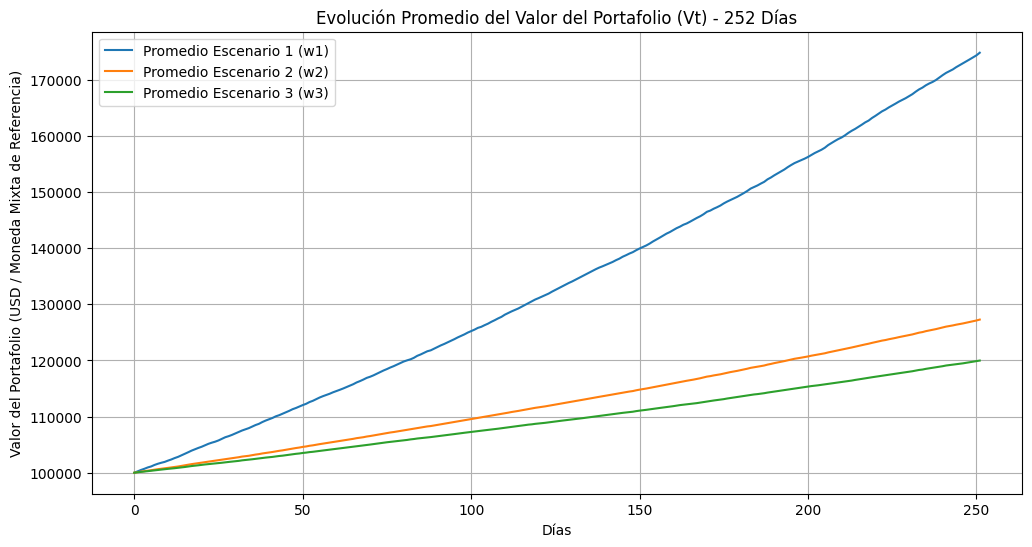

In [ ]:
# 5. Graficar la evolución promedio de Vt para cada escenario
plt.figure(figsize=(12, 6))
for name, Vt in portfolio_results.items():
    mean_Vt_path = Vt.mean(axis=1)
    plt.plot(mean_Vt_path, label=f"Promedio {name}")

plt.title('Evolución Promedio del Valor del Portafolio (Vt) - 252 Días')
plt.xlabel('Días')
plt.ylabel('Valor del Portafolio (USD / Moneda Mixta de Referencia)')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# 6. Mostrar estadísticas finales de Vt al término de 1 año (T=252)
for name, Vt in portfolio_results.items():
    final_Vt = Vt[-1, :]
    print(f"\nEstadísticas al final del año (Día 252) para {name}:")
    print(f"  Valor esperado promedio de Vt: {final_Vt.mean():.2f}")
    print(f"  Percentil 5% (Escenario adverso): {np.percentile(final_Vt, 5):.2f}")
    print(f"  Percentil 95% (Escenario favorable): {np.percentile(final_Vt, 95):.2f}")


Estadísticas al final del año (Día 252) para Escenario 1 (w1):
  Valor esperado promedio de Vt: 174779.13
  Percentil 5% (Escenario adverso): 73051.43
  Percentil 95% (Escenario favorable): 333119.58

Estadísticas al final del año (Día 252) para Escenario 2 (w2):
  Valor esperado promedio de Vt: 127265.11
  Percentil 5% (Escenario adverso): 87965.22
  Percentil 95% (Escenario favorable): 178744.57

Estadísticas al final del año (Día 252) para Escenario 3 (w3):
  Valor esperado promedio de Vt: 119969.06
  Percentil 5% (Escenario adverso): 86798.54
  Percentil 95% (Escenario favorable): 160098.70


### Simulación Multivariante con Conversión de Divisa (USD a MXN) por Trayectoria

Para que la conversión sea matemáticamente correcta, simulamos el tipo de cambio USD/MXN (`MXN=X`) de manera correlacionada con los activos. Luego, multiplicamos el precio de los activos en USD por el tipo de cambio simulado en cada instante $t$ y para cada camino $M$.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Definición de parámetros
V0_mxn = 100000  # Portafolio inicial en MXN
T_days = 252
M = 10000

# Activos financieros y tipo de cambio
assets = ['NVDA', 'BIMBOA', 'CEMEXCPO', 'AZN']
# Precios iniciales en su moneda de cotización de origen
S0_original = np.array([202.06, 66.18, 20.23, 186.58]) # NVDA (USD), BIMBO (MXN), CEMEX (MXN), AZN (USD)

# Necesitamos los datos históricos del tipo de cambio USD/MXN para la correlación conjunta
usd_mxn_close = data['Close']
if isinstance(usd_mxn_close, pd.DataFrame):
    usd_mxn_close = usd_mxn_close.iloc[:, 0]

# Alinear retornos históricos de activos y el tipo de cambio USD/MXN
log_returns_dict = {}
for asset in assets:
    close_col = historical_data[asset]['Close']
    if isinstance(close_col, pd.DataFrame):
        close_col = close_col.iloc[:, 0]
    log_returns_dict[asset] = np.log(close_col / close_col.shift(1)).dropna()

log_returns_dict['USD_MXN'] = np.log(usd_mxn_close / usd_mxn_close.shift(1)).dropna()

# DataFrame conjunto para calcular covarianza correlacionada
joint_returns_df = pd.DataFrame(log_returns_dict).dropna()

cov_matrix_joint = joint_returns_df.cov().values
mean_returns_joint = joint_returns_df.mean().values

# Factorización de Cholesky del sistema conjunto (5 variables: 4 activos + Tipo de Cambio)
L_joint = np.linalg.cholesky(cov_matrix_joint)

# 2. Simulación de Monte Carlo conjunta
# Guardaremos los resultados simulados de las 5 variables
simulated_paths = np.zeros((T_days, M, 5))

# Precios iniciales en moneda de origen + tipo de cambio inicial
USD_MXN_0 = usd_mxn_close.iloc[-1]
initial_values_joint = np.append(S0_original, USD_MXN_0)
simulated_paths[0, :, :] = initial_values_joint

for t in range(1, T_days):
    Z = np.random.normal(0, 1, (5, M))
    correlated_Z = np.dot(L_joint, Z).T
    drift = mean_returns_joint - 0.5 * np.diag(cov_matrix_joint)
    simulated_paths[t, :, :] = simulated_paths[t-1, :, :] * np.exp(drift + correlated_Z)

# Separar precios simulados de activos y tipo de cambio USD/MXN
simulated_assets = simulated_paths[:, :, :4]  # NVDA (USD), BIMBO (MXN), CEMEX (MXN), AZN (USD)
simulated_fx = simulated_paths[:, :, 4]      # USD/MXN

# 3. Conversión de activos a MXN en cada trayectoria y punto en el tiempo
simulated_prices_mxn = np.zeros_like(simulated_assets)

# NVDA (USD) -> Convertir a MXN
simulated_prices_mxn[:, :, 0] = simulated_assets[:, :, 0] * simulated_fx
# BIMBOA (MXN) -> Se queda igual
simulated_prices_mxn[:, :, 1] = simulated_assets[:, :, 1]
# CEMEXCPO (MXN) -> Se queda igual
simulated_prices_mxn[:, :, 2] = simulated_assets[:, :, 2]
# AZN (USD) -> Convertir a MXN
simulated_prices_mxn[:, :, 3] = simulated_assets[:, :, 3] * simulated_fx

# Precios iniciales en MXN para calcular la compra de acciones
S0_mxn = np.array([
    S0_original[0] * USD_MXN_0, # NVDA en MXN
    S0_original[1],             # BIMBO en MXN
    S0_original[2],             # CEMEX en MXN
    S0_original[3] * USD_MXN_0  # AZN en MXN
])

print(f"Tipo de cambio inicial utilizado (USD/MXN): {USD_MXN_0:.4f}")
print(f"Precios iniciales ajustados a MXN: NVDA={S0_mxn[0]:.2f}, BIMBOA={S0_mxn[1]:.2f}, CEMEXCPO={S0_mxn[2]:.2f}, AZN={S0_mxn[3]:.2f}")

Tipo de cambio inicial utilizado (USD/MXN): 18.5792
Precios iniciales ajustados a MXN: NVDA=3754.11, BIMBOA=66.18, CEMEXCPO=20.23, AZN=3466.51


In [ ]:
# 4. Distribución de pesos y simulación de escenarios del portafolio en MXN
weights_scenarios = {
    'Escenario 1 (w1)': np.array([1.0, 0.0, 0.0, 0.0]),
    'Escenario 2 (w2)': np.array([0.25, 0.25, 0.25, 0.25]),
    'Escenario 3 (w3)': np.array([0.1, 0.2, 0.3, 0.4])
}

portfolio_results_mxn = {}

for name, w in weights_scenarios.items():
    # Número de acciones adquiridas con los 100,000 MXN iniciales
    Ni = (w * V0_mxn) / S0_mxn
    print(f"\n--- {name} (Fondeado con {V0_mxn} MXN) ---")
    for asset, weight, n_shares in zip(assets, w, Ni):
        print(f"{asset}: Peso = {weight:.2f}, Acciones compradas (Ni) = {n_shares:.4f}")

    # Calcular valor diario del portafolio en pesos: Vt = sum(Ni_i * St_mxn_i)
    Vt_mxn = np.tensordot(simulated_prices_mxn, Ni, axes=(2, 0))
    portfolio_results_mxn[name] = Vt_mxn


--- Escenario 1 (w1) (Fondeado con 100000 MXN) ---
NVDA: Peso = 1.00, Acciones compradas (Ni) = 26.6374
BIMBOA: Peso = 0.00, Acciones compradas (Ni) = 0.0000
CEMEXCPO: Peso = 0.00, Acciones compradas (Ni) = 0.0000
AZN: Peso = 0.00, Acciones compradas (Ni) = 0.0000

--- Escenario 2 (w2) (Fondeado con 100000 MXN) ---
NVDA: Peso = 0.25, Acciones compradas (Ni) = 6.6594
BIMBOA: Peso = 0.25, Acciones compradas (Ni) = 377.7576
CEMEXCPO: Peso = 0.25, Acciones compradas (Ni) = 1235.7884
AZN: Peso = 0.25, Acciones compradas (Ni) = 7.2119

--- Escenario 3 (w3) (Fondeado con 100000 MXN) ---
NVDA: Peso = 0.10, Acciones compradas (Ni) = 2.6637
BIMBOA: Peso = 0.20, Acciones compradas (Ni) = 302.2061
CEMEXCPO: Peso = 0.30, Acciones compradas (Ni) = 1482.9461
AZN: Peso = 0.40, Acciones compradas (Ni) = 11.5390


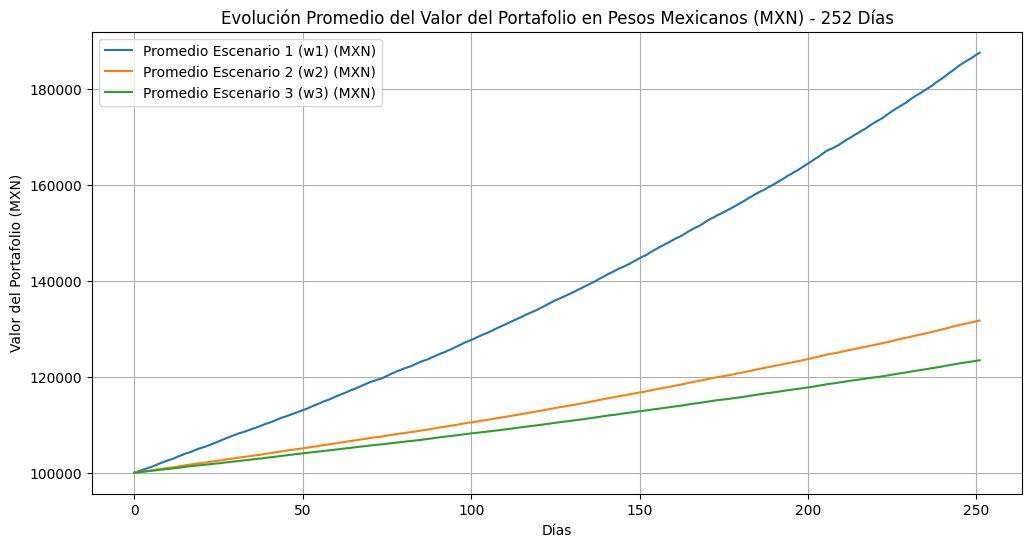

In [ ]:
# 5. Visualización del comportamiento del portafolio en pesos mexicanos (MXN)
plt.figure(figsize=(12, 6))
for name, Vt_mxn in portfolio_results_mxn.items():
    mean_Vt_path_mxn = Vt_mxn.mean(axis=1)
    plt.plot(mean_Vt_path_mxn, label=f"Promedio {name} (MXN)")

plt.title('Evolución Promedio del Valor del Portafolio en Pesos Mexicanos (MXN) - 252 Días')
plt.xlabel('Días')
plt.ylabel('Valor del Portafolio (MXN)')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# 6. Estadísticas finales al término de 1 año (T=252) en MXN
for name, Vt_mxn in portfolio_results_mxn.items():
    final_Vt_mxn = Vt_mxn[-1, :]
    print(f"\nEstadísticas al final del año (Día 252) para {name} en MXN:")
    print(f"  Valor esperado promedio de Vt: ${final_Vt_mxn.mean():.2f} MXN")
    print(f"  Percentil 5% (Escenario adverso): ${np.percentile(final_Vt_mxn, 5):.2f} MXN")
    print(f"  Percentil 95% (Escenario favorable): ${np.percentile(final_Vt_mxn, 95):.2f} MXN")


Estadísticas al final del año (Día 252) para Escenario 1 (w1) en MXN:
  Valor esperado promedio de Vt: $187578.77 MXN
  Percentil 5% (Escenario adverso): $75460.16 MXN
  Percentil 95% (Escenario favorable): $364440.90 MXN

Estadísticas al final del año (Día 252) para Escenario 2 (w2) en MXN:
  Valor esperado promedio de Vt: $131737.99 MXN
  Percentil 5% (Escenario adverso): $89006.80 MXN
  Percentil 95% (Escenario favorable): $189309.89 MXN

Estadísticas al final del año (Día 252) para Escenario 3 (w3) en MXN:
  Valor esperado promedio de Vt: $123446.77 MXN
  Percentil 5% (Escenario adverso): $87327.07 MXN
  Percentil 95% (Escenario favorable): $168349.38 MXN


### Histogramas de Distribución de los Escenarios Finales en MXN

A continuación, visualizaremos la distribución del valor final del portafolio ($V_{252}$) para los escenarios:
* **a**: Escenario 1 ($w_1$, 100% NVDA)
* **b**: Escenario 2 ($w_2$, equitativo)
* **c**: Escenario 3 ($w_3$, ponderado)

Utilizaremos transparencias (`alpha`) para comparar los traslapes y las colas de riesgo de cada estrategia.

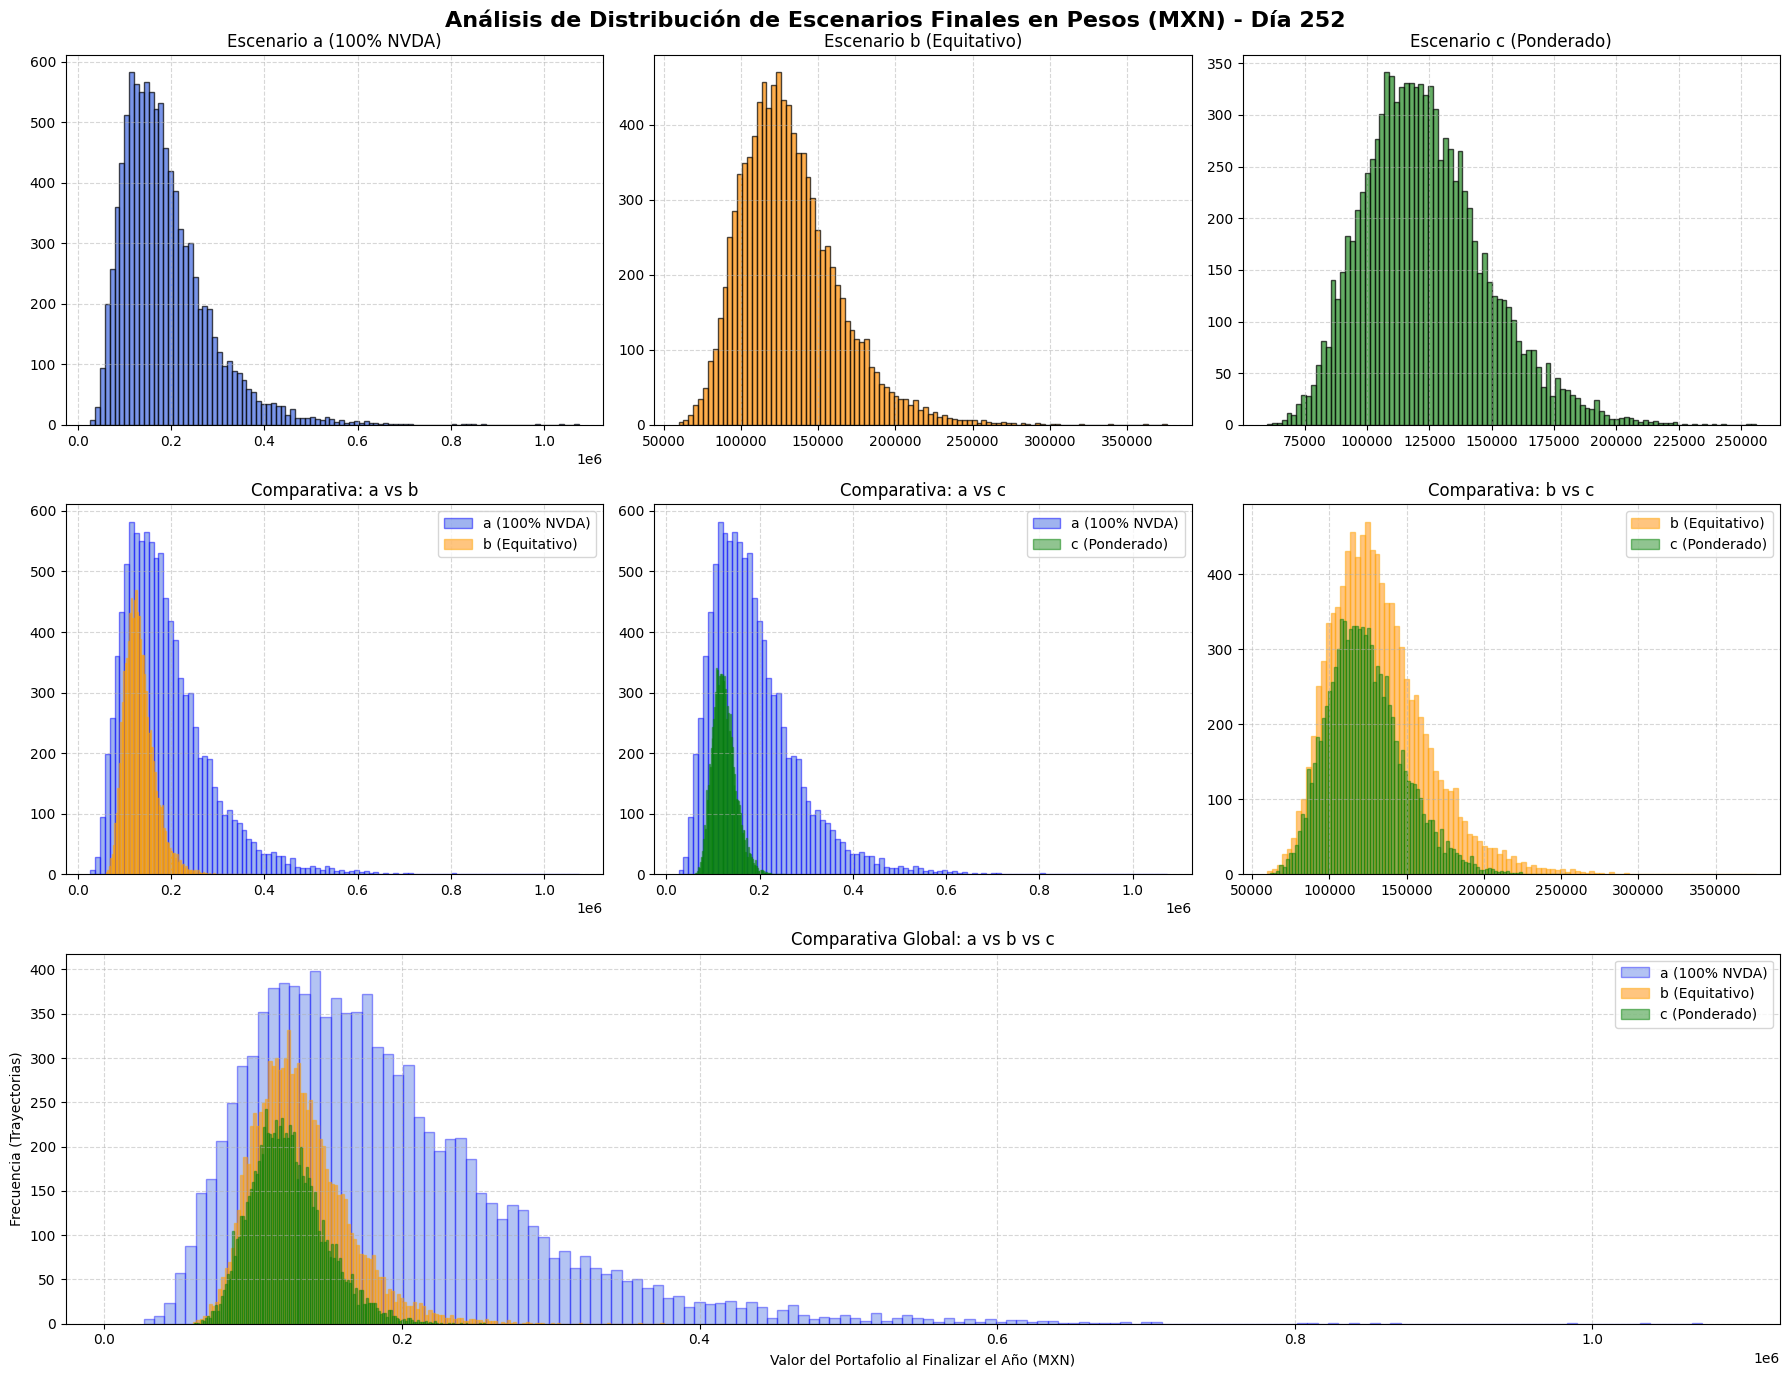

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Extraer los valores finales simulados (Día 252) para cada escenario
a = portfolio_results_mxn['Escenario 1 (w1)'][-1, :]
b = portfolio_results_mxn['Escenario 2 (w2)'][-1, :]
c = portfolio_results_mxn['Escenario 3 (w3)'][-1, :]

# Crear una figura con múltiples subgráficos
fig, axes = plt.subplots(3, 3, figsize=(18, 14), sharey=False)
fig.suptitle('Análisis de Distribución de Escenarios Finales en Pesos (MXN) - Día 252', fontsize=16, fontweight='bold')

# 1. Histogramas individuales
axes[0, 0].hist(a, bins=100, color='royalblue', alpha=0.7, edgecolor='black')
axes[0, 0].set_title('Escenario a (100% NVDA)')
axes[0, 0].grid(True, linestyle='--', alpha=0.5)

axes[0, 1].hist(b, bins=100, color='darkorange', alpha=0.7, edgecolor='black')
axes[0, 1].set_title('Escenario b (Equitativo)')
axes[0, 1].grid(True, linestyle='--', alpha=0.5)

axes[0, 2].hist(c, bins=100, color='forestgreen', alpha=0.7, edgecolor='black')
axes[0, 2].set_title('Escenario c (Ponderado)')
axes[0, 2].grid(True, linestyle='--', alpha=0.5)

# 2. Comparaciones por parejas
# a vs b
axes[1, 0].hist(a, bins=100, color='royalblue', alpha=0.5, label='a (100% NVDA)', edgecolor='blue')
axes[1, 0].hist(b, bins=100, color='darkorange', alpha=0.5, label='b (Equitativo)', edgecolor='orange')
axes[1, 0].set_title('Comparativa: a vs b')
axes[1, 0].legend()
axes[1, 0].grid(True, linestyle='--', alpha=0.5)

# a vs c
axes[1, 1].hist(a, bins=100, color='royalblue', alpha=0.5, label='a (100% NVDA)', edgecolor='blue')
axes[1, 1].hist(c, bins=100, color='forestgreen', alpha=0.5, label='c (Ponderado)', edgecolor='green')
axes[1, 1].set_title('Comparativa: a vs c')
axes[1, 1].legend()
axes[1, 1].grid(True, linestyle='--', alpha=0.5)

# b vs c
axes[1, 2].hist(b, bins=100, color='darkorange', alpha=0.5, label='b (Equitativo)', edgecolor='orange')
axes[1, 2].hist(c, bins=100, color='forestgreen', alpha=0.5, label='c (Ponderado)', edgecolor='green')
axes[1, 2].set_title('Comparativa: b vs c')
axes[1, 2].legend()
axes[1, 2].grid(True, linestyle='--', alpha=0.5)

# 3. Comparación global (a vs b vs c) en un panel grande abajo
ax_big = plt.subplot(3, 1, 3)
ax_big.hist(a, bins=150, color='royalblue', alpha=0.4, label='a (100% NVDA)', edgecolor='blue')
ax_big.hist(b, bins=150, color='darkorange', alpha=0.5, label='b (Equitativo)', edgecolor='orange')
ax_big.hist(c, bins=150, color='forestgreen', alpha=0.5, label='c (Ponderado)', edgecolor='green')
ax_big.set_title('Comparativa Global: a vs b vs c')
ax_big.set_xlabel('Valor del Portafolio al Finalizar el Año (MXN)')
ax_big.set_ylabel('Frecuencia (Trayectorias)')
ax_big.legend()
ax_big.grid(True, linestyle='--', alpha=0.5)

# Desactivar los ejes sobrantes que no se usan
fig.delaxes(axes[2, 0])
fig.delaxes(axes[2, 1])
fig.delaxes(axes[2, 2])

plt.tight_layout()
plt.show()

# Día 16

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

In [ ]:
tickers = ["AAPl", "MSFT", "NVDA", ]
prices= yf.download(tickers=tickers, start="2023-11-01", end="2026-11-01")["Close"]


/tmp/ipykernel_915/3500542863.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices= yf.download(tickers=tickers, start="2023-11-01", end="2026-11-01")["Close"]
[*********************100%***********************]  3 of 3 completed


In [ ]:
rets =np.log(prices/prices.shift(-1)).dropna()
rets

Ticker,AAPL,MSFT,NVDA
Date,,,
2023-11-01,-0.020482,-0.006481,-0.027521
2023-11-02,0.005195,-0.012780,-0.033875
2023-11-03,-0.014499,-0.010517,-0.016440
2023-11-06,-0.014347,-0.011157,-0.004449
2023-11-07,-0.005868,-0.007378,-0.013380
...,...,...,...
2026-10-23,0.011046,-0.015306,-0.023610
2026-10-26,-0.009233,0.002387,-0.008941
2026-10-27,0.009466,0.000602,0.011816


In [ ]:
# Matriz epsilon
rets.corr()

Ticker,AAPL,MSFT,NVDA
Ticker,,,
AAPL,1.000000,0.334250,0.284358
MSFT,0.334250,1.000000,0.421861
NVDA,0.284358,0.421861,1.000000


In [ ]:
import numpy as np
import pandas as pd

# 1. Calcular la matriz de covarianza diaria de los retornos y llamarla SIGMA
SIGMA = rets.cov().values
print("Matriz de Covarianza (SIGMA):")
print(SIGMA)

# 2. Descomponer L usando la factorización de Cholesky
L = np.linalg.cholesky(SIGMA)
print("\nMatriz L (Cholesky):")
print(L)

# Verificar LL^T (L por su transpuesta)
LL_transposed = np.dot(L, L.T)
print("\nVerificación de LL^T (debe ser idéntica a SIGMA):")
print(LL_transposed)

# 3. Calcular la media (miu) de los retornos
miu = rets.mean().values.reshape(-1, 1)  # Darle forma de vector columna
print("\nVector de Medias (miu):")
print(miu)

# 4. Simular epsilon con N(0, I)
# Simularemos, por ejemplo, 10,000 escenarios
num_simulaciones = 10000
num_activos = len(tickers)

# epsilon tiene forma (num_activos, num_simulaciones)
epsilon = np.random.normal(0, 1, size=(num_activos, num_simulaciones))

# 5. Transformar Z = miu + L * epsilon
# Se aplica la transformación lineal para correlacionar las variables simuladas
Z = miu + np.dot(L, epsilon)

print(f"\nSimulación completada con éxito. Epsilon y Z generados con forma: {Z.shape}")

Matriz de Covarianza (SIGMA):
[[2.82498207e-04 9.17168379e-05 1.40178864e-04]
 [9.17168379e-05 2.66525554e-04 2.01997920e-04]
 [1.40178864e-04 2.01997920e-04 8.60234973e-04]]

Matriz L (Cholesky):
[[0.01680768 0.         0.        ]
 [0.00545684 0.01538663 0.        ]
 [0.00834017 0.01017032 0.02621529]]

Verificación de LL^T (debe ser idéntica a SIGMA):
[[2.82498207e-04 9.17168379e-05 1.40178864e-04]
 [9.17168379e-05 2.66525554e-04 2.01997920e-04]
 [1.40178864e-04 2.01997920e-04 8.60234973e-04]]

Vector de Medias (miu):
[[-0.00092813]
 [-0.0005779 ]
 [-0.00210234]]

Simulación completada con éxito. Epsilon y Z generados con forma: (3, 10000)


In [ ]:
import pandas as pd

# Obtener los nombres de los activos para usar como índices y columnas
asset_names = tickers

# 1. Matriz de Covarianza (SIGMA) como tabla
df_sigma = pd.DataFrame(SIGMA, index=asset_names, columns=asset_names)
print("Matriz de Covarianza (SIGMA):")
display(df_sigma)

# 2. Matriz de Cholesky (L) como tabla
df_L = pd.DataFrame(L, index=asset_names, columns=asset_names)
print("\nMatriz L de Cholesky:")
display(df_L)

# 3. Muestra de las simulaciones de Epsilon (N(0, I))
# Mostramos las primeras 5 simulaciones (columnas) para cada activo (filas)
column_names = [f"Escenario_{i+1}" for i in range(num_simulaciones)]
df_epsilon = pd.DataFrame(epsilon, index=asset_names, columns=column_names)
print("\nMuestra de la Matriz Epsilon (Primeros 5 escenarios simulados):")
display(df_epsilon.iloc[:, :5])

# 4. Muestra de los retornos correlacionados Z (N(miu, SIGMA))
df_Z = pd.DataFrame(Z, index=asset_names, columns=column_names)
print("\nMuestra de la Matriz Z Correlacionada (Primeros 5 univ simulados):")
display(df_Z.iloc[:, :5])

Matriz de Covarianza (SIGMA):


,AAPl,MSFT,NVDA
AAPl,0.000282,0.000092,0.000140
MSFT,0.000092,0.000267,0.000202
NVDA,0.000140,0.000202,0.000860



Matriz L de Cholesky:


,AAPl,MSFT,NVDA
AAPl,0.016808,0.000000,0.000000
MSFT,0.005457,0.015387,0.000000
NVDA,0.008340,0.010170,0.026215



Muestra de la Matriz Epsilon (Primeros 5 escenarios simulados):


,Escenario_1,Escenario_2,Escenario_3,Escenario_4,Escenario_5
AAPl,-1.014769,0.227949,-1.033776,0.320109,0.703535
MSFT,0.524101,0.998641,2.111923,1.731884,0.561830
NVDA,-0.049070,1.527133,1.025710,-0.403286,-1.068563



Muestra de la Matriz Z Correlacionada (Primeros 5 univ simulados):


,Escenario_1,Escenario_2,Escenario_3,Escenario_4,Escenario_5
AAPl,-0.017984,0.002903,-0.018304,0.004452,0.010897
MSFT,0.001949,0.016032,0.026276,0.027817,0.011906
NVDA,-0.006522,0.049990,0.037644,0.007609,-0.018533


In [ ]:
# 1. Obtener el último precio histórico real de cada activo
S0_assets = prices.iloc[-1].values.reshape(-1, 1) # Forma (3, 1)

# 2. Calcular el precio proyectado St para cada escenario:
# St = S0 * exp(Z)
St_matrix = S0_assets * np.exp(Z)

# 3. Guardar y mostrar los resultados de St como una tabla de Pandas
df_St = pd.DataFrame(St_matrix, index=asset_names, columns=column_names)

print("Precios históricos de partida (S0):")
for name, price in zip(asset_names, S0_assets.flatten()):
    print(f"  {name}: {price:.2f}")

print("\nMuestra de los precios proyectados (St) para los primeros 5 universos:")
display(df_St.iloc[:, :5])

Precios históricos de partida (S0):
  AAPl: 344.63
  MSFT: 521.91
  NVDA: 204.64

Muestra de los precios proyectados (St) para los primeros 5 universos:


,Escenario_1,Escenario_2,Escenario_3,Escenario_4,Escenario_5
AAPl,338.487564,345.631979,338.379447,346.167773,348.405859
MSFT,522.928068,530.344509,535.805617,536.631616,528.160888
NVDA,203.309725,215.129861,212.490301,206.203041,200.882245


### Tarea

/tmp/ipykernel_546/3185522547.py:8: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices = yf.download(tickers=tickers, start="2023-11-01", end="2026-11-01")["Close"]
[*********************100%***********************]  3 of 3 completed


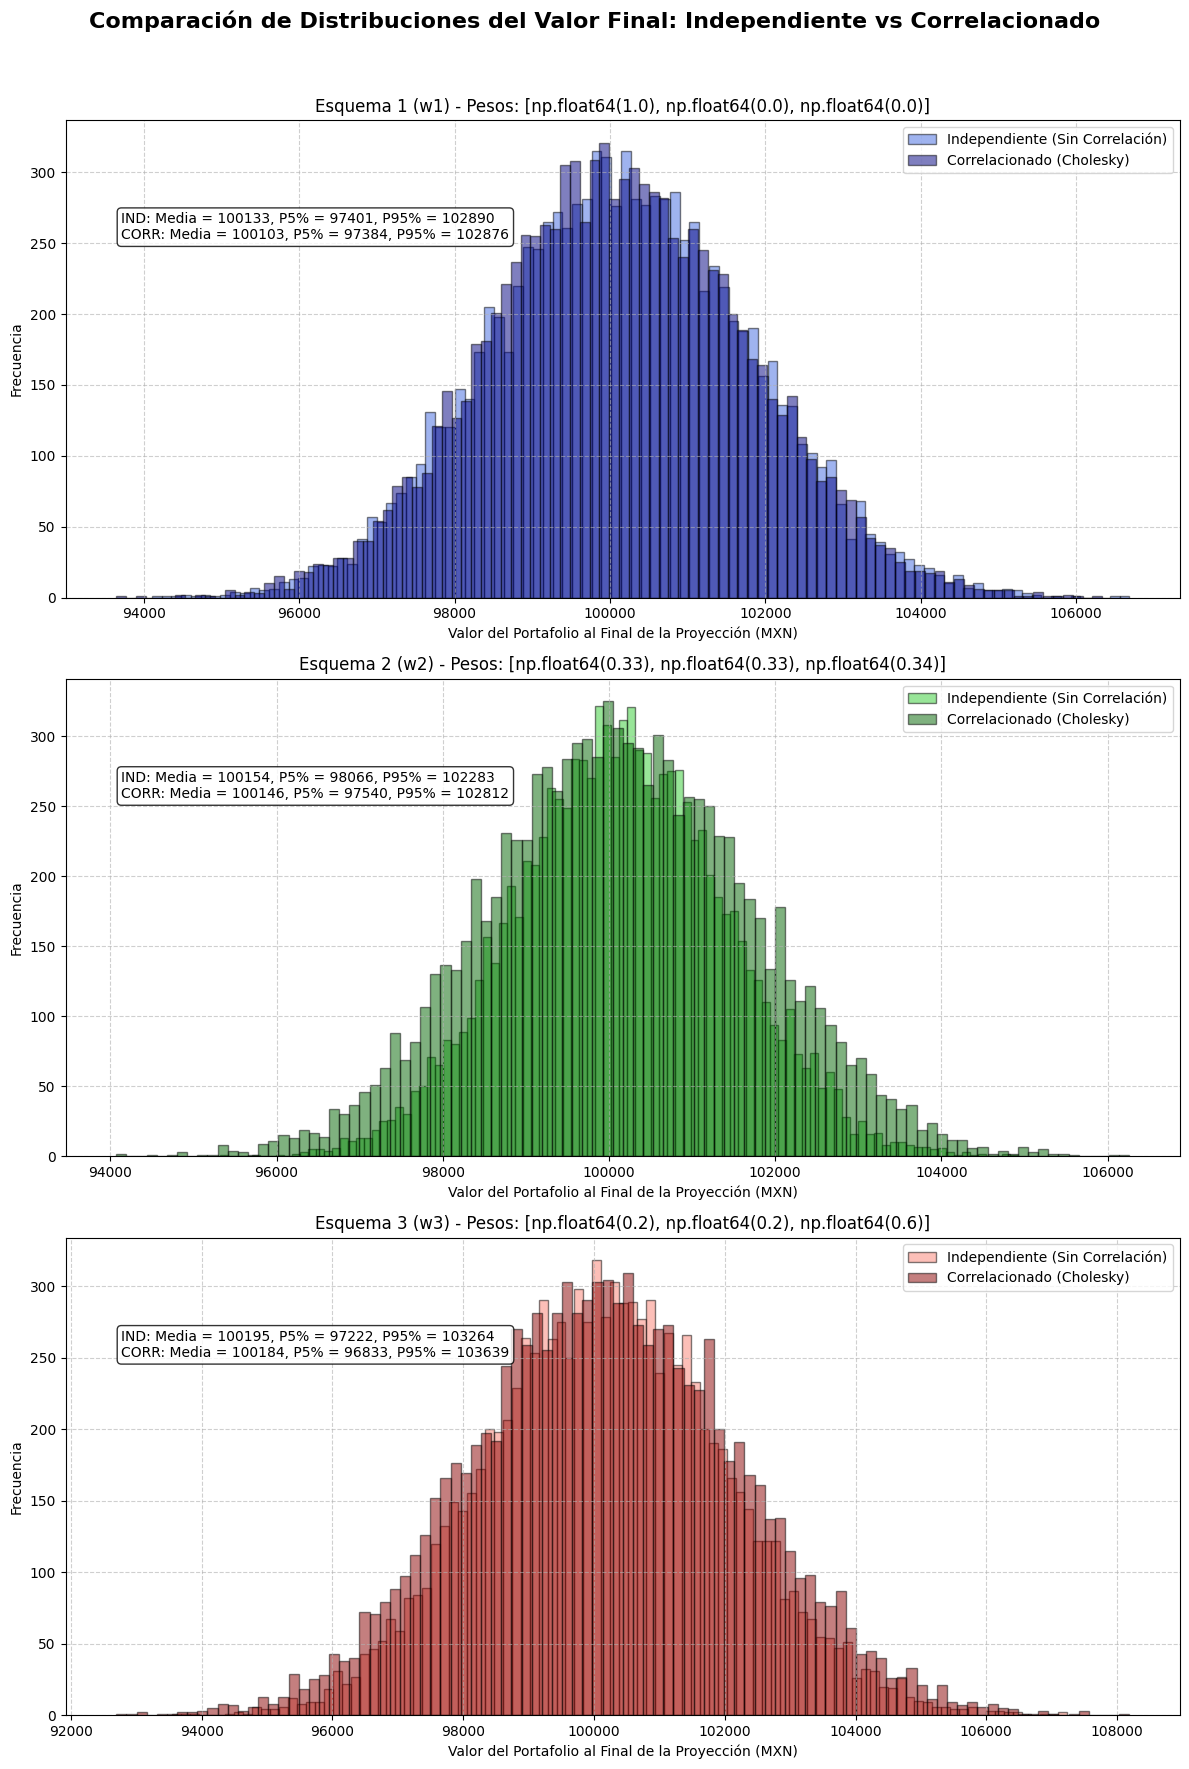

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

# 1. Descargar datos históricos para garantizar que existan en el espacio de nombres
tickers = ["AAPL", "MSFT", "NVDA"]
prices = yf.download(tickers=tickers, start="2023-11-01", end="2026-11-01")["Close"]

# Calcular retornos logarítmicos
rets = np.log(prices / prices.shift(1)).dropna()

# Configurar parámetros estadísticos reales
SIGMA = rets.cov().values
miu = rets.mean().values.reshape(-1, 1)
L = np.linalg.cholesky(SIGMA)

num_simulaciones = 10000
num_activos = len(tickers)

# Generar retornos correlacionados (Z) mediante Cholesky
epsilon = np.random.normal(0, 1, size=(num_activos, num_simulaciones))
Z = miu + np.dot(L, epsilon)

# 2. Definir parámetros iniciales del portafolio
V0 = 100000
weights_b = {
    'Esquema 1 (w1)': np.array([1.0, 0.0, 0.0]),
    'Esquema 2 (w2)': np.array([0.33, 0.33, 0.34]),
    'Esquema 3 (w3)': np.array([0.2, 0.2, 0.6])
}

# Precios iniciales históricos reales de partida (S0)
S0 = prices.iloc[-1].values  # Forma (3,)

# 3. Simulación de Retornos Independientes (usando sigmas individuales de la diagonal de SIGMA)
sigmas_diag = np.sqrt(np.diag(SIGMA)).reshape(-1, 1)
epsilon_ind = np.random.normal(0, 1, size=(num_activos, num_simulaciones))
Z_ind = miu + sigmas_diag * epsilon_ind

# 4. Precios proyectados St para ambos casos
St_correlated = S0.reshape(-1, 1) * np.exp(Z)          # (3, 10000)
St_independent = S0.reshape(-1, 1) * np.exp(Z_ind)      # (3, 10000)

# 5. Evaluación de los escenarios del portafolio
portfolio_corr = {}
portfolio_ind = {}

for name, w in weights_b.items():
    # Número de acciones adquiridas con el capital inicial V0
    Ni = (w * V0) / S0

    # Valor final del portafolio bajo ambos enfoques
    Vt_corr = np.dot(Ni, St_correlated)
    Vt_ind = np.dot(Ni, St_independent)

    portfolio_corr[name] = Vt_corr
    portfolio_ind[name] = Vt_ind

# 6. Graficar comparativa de Distribuciones
fig, axes = plt.subplots(3, 1, figsize=(12, 18), sharex=False)
fig.suptitle('Comparación de Distribuciones del Valor Final: Independiente vs Correlacionado', fontsize=16, fontweight='bold')

colors_corr = ['navy', 'darkgreen', 'darkred']
colors_ind = ['royalblue', 'limegreen', 'salmon']

for idx, (name, w) in enumerate(weights_b.items()):
    ax = axes[idx]
    corr_data = portfolio_corr[name]
    ind_data = portfolio_ind[name]

    ax.hist(ind_data, bins=100, color=colors_ind[idx], alpha=0.5, label='Independiente (Sin Correlación)', edgecolor='black')
    ax.hist(corr_data, bins=100, color=colors_corr[idx], alpha=0.5, label='Correlacionado (Cholesky)', edgecolor='black')

    ax.set_title(f'{name} - Pesos: {list(w)}')
    ax.set_xlabel('Valor del Portafolio al Final de la Proyección (MXN)')
    ax.set_ylabel('Frecuencia')
    ax.legend()
    ax.grid(True, linestyle='--', alpha=0.6)

    # Agregar estadísticas rápidas en texto dentro de la gráfica
    txt = (f"IND: Media = {ind_data.mean():.0f}, P5% = {np.percentile(ind_data, 5):.0f}, P95% = {np.percentile(ind_data, 95):.0f}\n"
           f"CORR: Media = {corr_data.mean():.0f}, P5% = {np.percentile(corr_data, 5):.0f}, P95% = {np.percentile(corr_data, 95):.0f}")
    ax.text(0.05, 0.75, txt, transform=ax.transAxes, fontsize=10, bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### Observaciones y Análisis de Resultados (Punto 2):

1. **Esquema 1 (`[1, 0, 0]`) - 100% AAPL:**
   * Al estar concentrado al 100% en un único activo, la simulación correlacionada y la independiente hacen resultados idénticos o muy cercanos en su distribución. Esto porque no hay diversificación de las acciones.

2. **Esquemas Diversificados (`w2` y `w3`):**
   * **Dispersión (Varianza):** En la distribución del portafolio **independiente**, la variabilidad es menor. al asumir independencia, las variaciones de unos activos se cancelan con las de los otros.
   * **Riesgo y colas correlacionadas:** En la versión **correlacionada**, vemos que la dispersión (la anchura del histograma) es mayor. Como los activos se mueven juntos con frecuencia debido a shocks de mercado compartidos (particularmente en el sector tecnológico), el portafolio correlacionado experimenta caídas más profundas (un percentil 5% más bajo) y ganancias máximas mayores (un percentil 95% más alto). El beneficio de la diversificación real es menor que el que predice el modelo simplista de independencia.